In [1]:
# 1. Imports
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU available: []


In [2]:
# 2. Load and preprocess MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Train shape:", x_train.shape, "Test shape:", x_test.shape)

# Flattened version for the ANN
x_train_flat = x_train.reshape(-1, 28 * 28)
x_test_flat = x_test.reshape(-1, 28 * 28)

# Channel dimension added for the CNN
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train shape: (60000, 28, 28) Test shape: (10000, 28, 28)


In [3]:
def build_ann():
    model = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(256, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

ann_model = build_ann()
ann_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

cnn_model = build_cnn()
cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
EPOCHS = 10
BATCH_SIZE = 128

# Train ANN
start = time.time()
ann_history = ann_model.fit(
    x_train_flat, y_train,
    validation_data=(x_test_flat, y_test),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2
)
ann_time = time.time() - start
print(f"ANN training time: {ann_time:.2f} seconds")


Epoch 1/10
469/469 - 5s - 11ms/step - accuracy: 0.9230 - loss: 0.2688 - val_accuracy: 0.9567 - val_loss: 0.1389
Epoch 2/10
469/469 - 6s - 13ms/step - accuracy: 0.9695 - loss: 0.1013 - val_accuracy: 0.9724 - val_loss: 0.0904
Epoch 3/10
469/469 - 4s - 8ms/step - accuracy: 0.9802 - loss: 0.0649 - val_accuracy: 0.9729 - val_loss: 0.0826
Epoch 4/10
469/469 - 4s - 8ms/step - accuracy: 0.9849 - loss: 0.0485 - val_accuracy: 0.9789 - val_loss: 0.0681
Epoch 5/10
469/469 - 5s - 11ms/step - accuracy: 0.9893 - loss: 0.0342 - val_accuracy: 0.9773 - val_loss: 0.0771
Epoch 6/10
469/469 - 4s - 8ms/step - accuracy: 0.9916 - loss: 0.0263 - val_accuracy: 0.9791 - val_loss: 0.0726
Epoch 7/10
469/469 - 4s - 8ms/step - accuracy: 0.9933 - loss: 0.0215 - val_accuracy: 0.9774 - val_loss: 0.0801
Epoch 8/10
469/469 - 5s - 11ms/step - accuracy: 0.9949 - loss: 0.0159 - val_accuracy: 0.9789 - val_loss: 0.0765
Epoch 9/10
469/469 - 4s - 8ms/step - accuracy: 0.9946 - loss: 0.0171 - val_accuracy: 0.9776 - val_loss: 0.08

In [6]:
# Train CNN
start = time.time()
cnn_history = cnn_model.fit(
    x_train_cnn, y_train,
    validation_data=(x_test_cnn, y_test),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2
)
cnn_time = time.time() - start
print(f"CNN training time: {cnn_time:.2f} seconds")


Epoch 1/10
469/469 - 49s - 104ms/step - accuracy: 0.9431 - loss: 0.1943 - val_accuracy: 0.9822 - val_loss: 0.0574
Epoch 2/10
469/469 - 46s - 98ms/step - accuracy: 0.9827 - loss: 0.0561 - val_accuracy: 0.9878 - val_loss: 0.0380
Epoch 3/10
469/469 - 81s - 174ms/step - accuracy: 0.9887 - loss: 0.0381 - val_accuracy: 0.9851 - val_loss: 0.0444
Epoch 4/10
469/469 - 45s - 97ms/step - accuracy: 0.9909 - loss: 0.0291 - val_accuracy: 0.9877 - val_loss: 0.0349
Epoch 5/10
469/469 - 81s - 174ms/step - accuracy: 0.9933 - loss: 0.0226 - val_accuracy: 0.9886 - val_loss: 0.0353
Epoch 6/10
469/469 - 48s - 102ms/step - accuracy: 0.9950 - loss: 0.0170 - val_accuracy: 0.9882 - val_loss: 0.0335
Epoch 7/10
469/469 - 79s - 169ms/step - accuracy: 0.9957 - loss: 0.0133 - val_accuracy: 0.9919 - val_loss: 0.0260
Epoch 8/10
469/469 - 46s - 99ms/step - accuracy: 0.9962 - loss: 0.0123 - val_accuracy: 0.9915 - val_loss: 0.0295
Epoch 9/10
469/469 - 45s - 96ms/step - accuracy: 0.9965 - loss: 0.0102 - val_accuracy: 0.99

In [7]:
ann_loss, ann_acc = ann_model.evaluate(x_test_flat, y_test, verbose=0)
cnn_loss, cnn_acc = cnn_model.evaluate(x_test_cnn, y_test, verbose=0)

print(f"{'Model':<10}{'Test Accuracy':<18}{'Test Loss':<15}{'Training Time (s)'}")
print(f"{'ANN':<10}{ann_acc:<18.4f}{ann_loss:<15.4f}{ann_time:.2f}")
print(f"{'CNN':<10}{cnn_acc:<18.4f}{cnn_loss:<15.4f}{cnn_time:.2f}")


Model     Test Accuracy     Test Loss      Training Time (s)
ANN       0.9789            0.0761         44.66
CNN       0.9898            0.0341         604.19


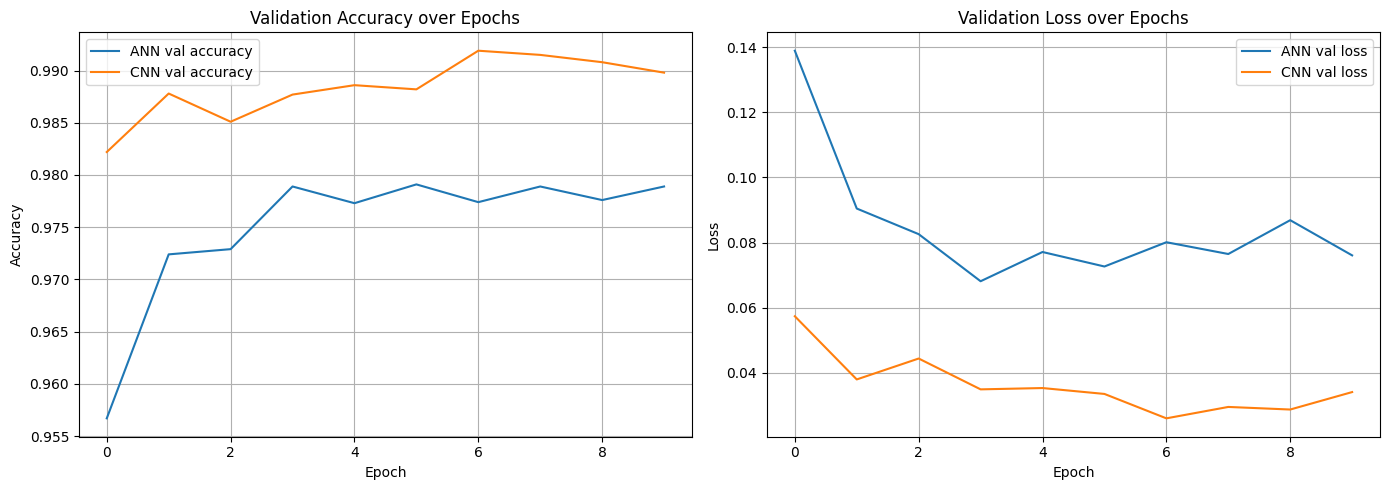

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(ann_history.history['val_accuracy'], label='ANN val accuracy')
axes[0].plot(cnn_history.history['val_accuracy'], label='CNN val accuracy')
axes[0].set_title('Validation Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(ann_history.history['val_loss'], label='ANN val loss')
axes[1].plot(cnn_history.history['val_loss'], label='CNN val loss')
axes[1].set_title('Validation Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [9]:
print("""
ANALYSIS: CNN vs ANN on MNIST
------------------------------------------------
Test Accuracy -> ANN: {:.4f} | CNN: {:.4f}
Training Time -> ANN: {:.2f}s | CNN: {:.2f}s

The CNN typically achieves higher accuracy because it preserves spatial
relationships between pixels via convolutional filters, uses parameter
sharing (fewer parameters, less overfitting), and is translation-invariant
(can detect a feature anywhere in the image). The ANN treats every pixel as
an independent input feature after flattening, losing all spatial context,
so it must learn far more redundant patterns and generalizes worse on image
data.
""".format(ann_acc, cnn_acc, ann_time, cnn_time))



ANALYSIS: CNN vs ANN on MNIST
------------------------------------------------
Test Accuracy -> ANN: 0.9789 | CNN: 0.9898
Training Time -> ANN: 44.66s | CNN: 604.19s

The CNN typically achieves higher accuracy because it preserves spatial
relationships between pixels via convolutional filters, uses parameter
sharing (fewer parameters, less overfitting), and is translation-invariant
(can detect a feature anywhere in the image). The ANN treats every pixel as
an independent input feature after flattening, losing all spatial context,
so it must learn far more redundant patterns and generalizes worse on image
data.

